# Би-/триграммы и OpenIE

Сравнение на 1000 текстах и 10 человеческих разметках. Лексическое покрытие не является семантической точностью. Промпт и сохранённые ответы модели не изменены.

In [1]:
from pathlib import Path
import sys, io, contextlib
from IPython.display import display, Markdown, Image
import pandas as pd
root = Path.cwd().resolve()
if not (root/"compare_methods.py").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import compare_methods as c

In [2]:
with contextlib.redirect_stdout(io.StringIO()):
    statistics = c.main()
display(pd.read_csv(c.OUT/"human_word_coverage.csv"))
display(Markdown((c.OUT/"README.md").read_text(encoding="utf-8").split("## Измеренные различия")[0]))

,id,human_relations,ngram_word_coverage,openie_word_coverage
0,gazeta_18651,3,0.176471,0.352941
1,gazeta_46346,3,0.400000,0.250000
2,gazeta_44496,3,0.181818,0.363636
3,gazeta_12827,2,0.333333,0.416667
4,gazeta_35151,3,0.400000,0.533333
5,gazeta_18627,2,0.357143,0.142857
6,gazeta_19567,3,0.181818,0.818182
7,gazeta_25263,3,0.222222,0.333333
8,gazeta_38485,3,0.250000,0.625000
9,gazeta_25226,2,0.000000,0.750000


# Би-/триграммы и OpenIE: сравнение

## Что проверено

Одна выборка: 1000 редакционных аннотаций Gazeta. Для каждого текста восстановлены прежние 6 лучших би-/триграмм TF–IDF и взяты сохранённые OpenIE-связи Qwen. Параметры TF–IDF и фильтр крайних стоп-слов повторяют прежнюю реализацию; файл `ngrams.jsonl` позволяет проверить восстановление по SHA-256. Дополнительных запросов к модели нет.

**Качество ответов Qwen после удаления n-грамм не изменилось:** сами ответы и промпт остались прежними. Сравниваются два представления одного текста, а не две версии модели. Шесть бинарных признаков составляют отдельную задачу.



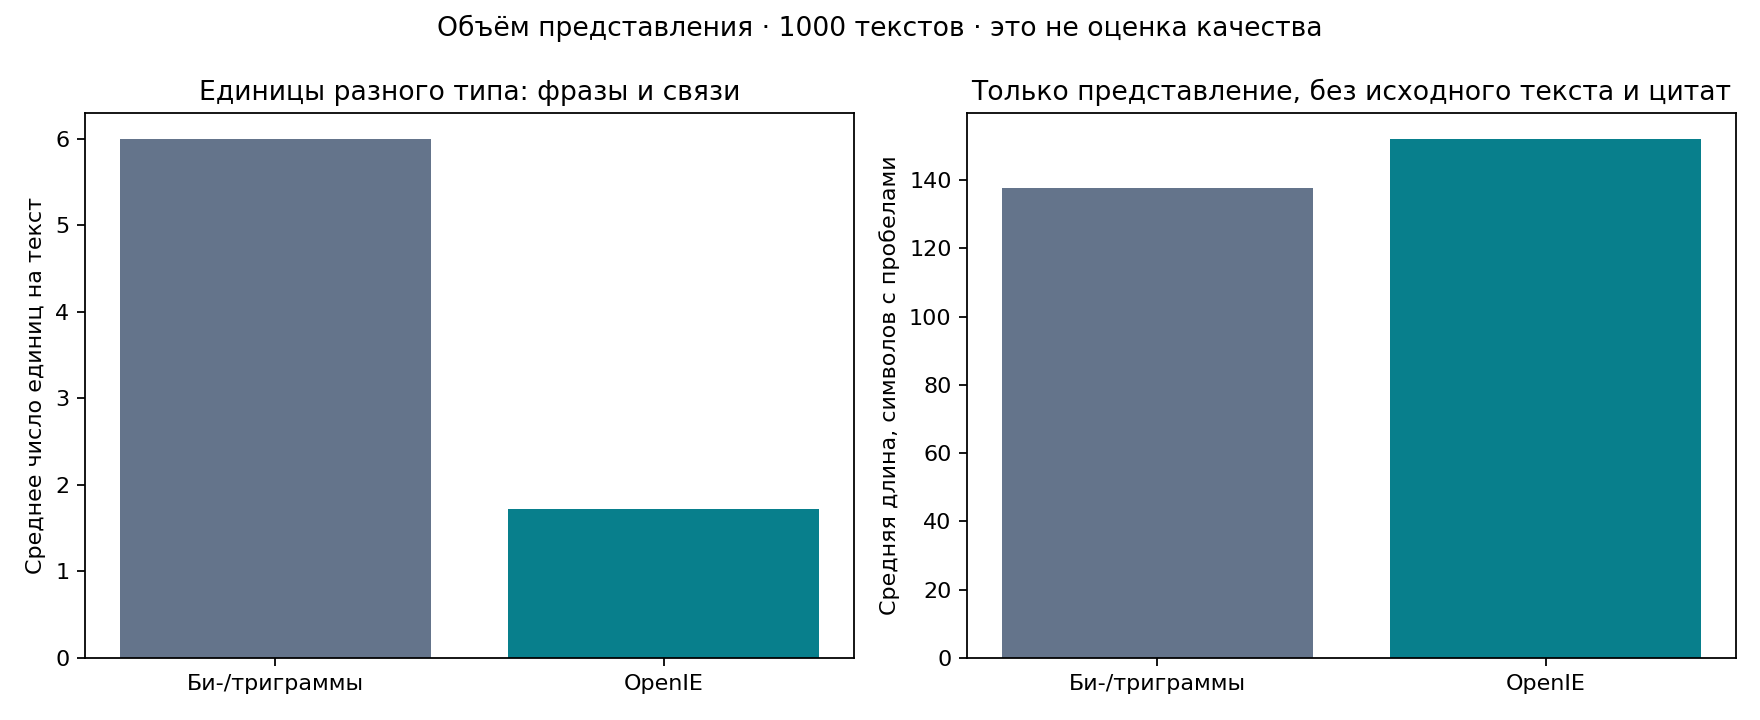

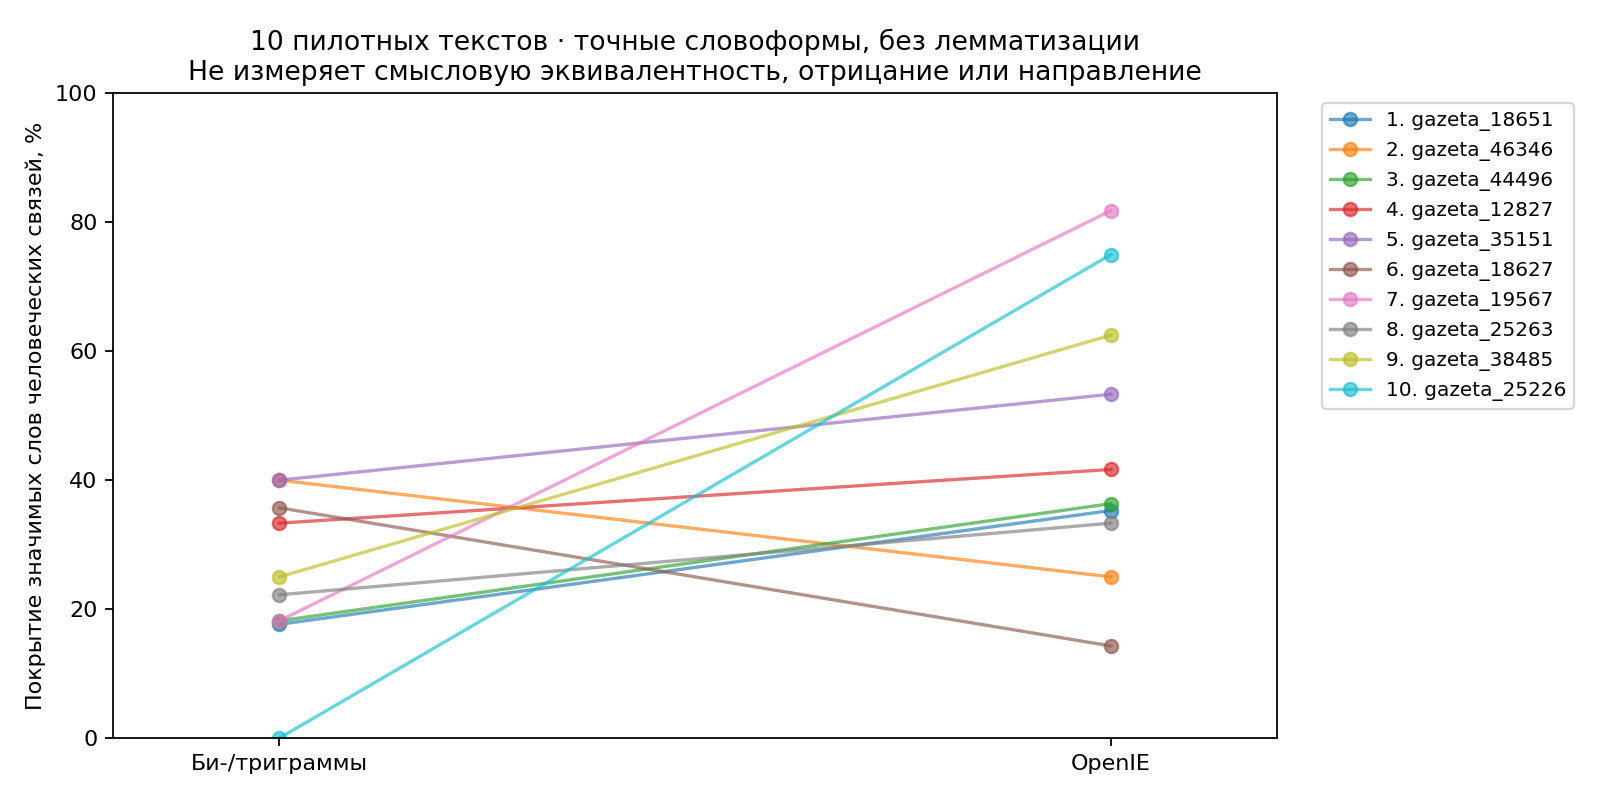

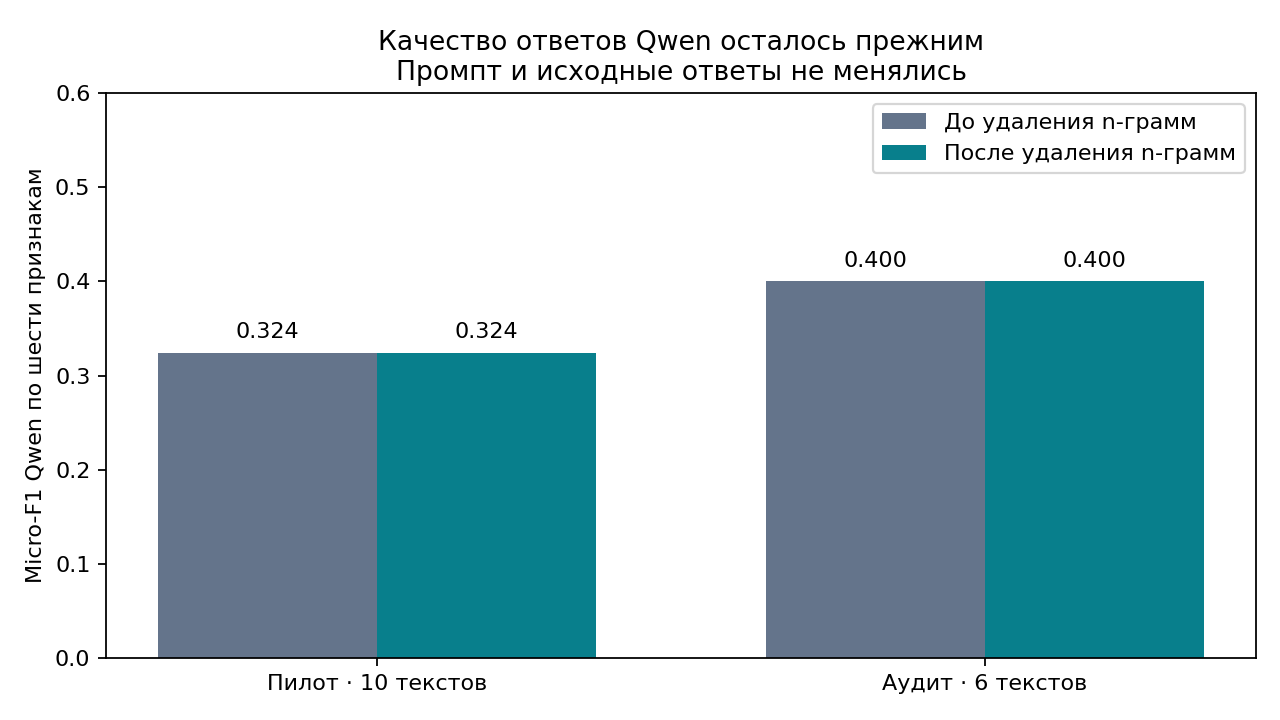

In [3]:
for name in ["representation.png", "human_word_coverage.png", "quality_before_after.png"]:
    display(Image(filename=str(c.OUT/name)))